# **Basics of Mobile Robotics - Project Report**
### **Professor Francesco Mondada**
### **EPFL – Fall 2025**

---

## **Group 14**
- **Jules Villaret** — Global Navigation  
- **Tim Kobler** — Filtering  
- **Amir Lahlou** — Vision  
- **Ana Schwabedal** — Local Navigation & Motion Control  

---

## **Table of Contents**

1. [**Introduction**](#introduction)  
2. [**Choice of Environment**](#choice-of-environment)  
3. [**Vision**](#vision)  
4. [**Global Navigation**](#global-navigation)  
5. [**Motion Control**](#motion-control)  
6. [**Local Navigation**](#local-navigation)  
7. [**Filtering**](#filtering)  
8. [**Full System Integration**](#full-system-integration)  
9. [**Conclusion**](#conclusion)  
10. [**References & Disclaimers**](#references--disclaimers)

## 1. Introduction
Imagine a small robot casually exploring the surface of the Moon. A dust storm is approaching, and the robot must autonomously navigate through craters and rock to return safely to its lander. To succeed, it must perceive its surroundings, estimate its position despite uncertainty, plan a safe route, and react instantly to unexpected obstacles.

In this project, we recreate this scenario using the Thymio robot. Our goal is to design a complete navigation system that allows the robot to move reliably through a predefined map, reach a target placed anywhere in the environment and avoid both known and unexpected obstacles. The Thymio relies on an overhead camera for global pose estimation, an Extended Kalman Filter to correct odometry drift, and proximity sensors for reactive obstacle avoidance.

This report presents the main design choices and algorithms used to achieve these tasks. It follows the structure recommended in the MICRO-452 Basics of Mobile Robotics course taught by Prof. Francesco Mondada, and details the different modules of our system: computer vision, global navigation, filtering, local navigation and motion control.

## Demonstration Video
*Below is a visualization of the robot's movement accross the environment.*


[![Video preview](Images%20and%20Videos/thumbnail.png)](Images%20and%20Videos/demonstration.mp4)

---
## 2. Choice of Environment 
### Environment Setup and Design Decisions
---

### 2.1 Choice of map

We deliberately chose a simple, open environment to make the overall system more robust and easier to control. The arena contains only a few large, chunky obstacles with no narrow passages, ensuring that the robot can perform smooth avoidance manoeuvres without requiring precise positioning. The environment is asymmetric so that localisation remains unambiguous, and it leaves plenty of open space for mobile obstacles.
To support reliable vision-based localisation, we placed several high-contrast ArUco markers around the map. Using four markers maintains stable pose estimation across the entire workspace. AruCo markers were also the most reliable choice for identifying the robot as well as the goal.
This environment works well because it maximises contrast, simplifies perception, avoids tight geometric constraints, and provides a reliable visual reference frame for the robot’s navigation and filtering.

### 2.2 Choice of obstacles

Obstacles can be detected using the IR sensors. These work by emitting infrared light, and then measuring how much of that light bounces back (a lot of light returning means the object is close, otherwise the object is far away). Obstacles that are too dark cause the light to be absorbed and the robot doesn’t detect them until they are very close. Thus they were avoided. Cardboard covered with a white sheet of paper or even just paper are reliable choices. Thus, a plain white paper cylinder was used as the obstacle of chocie.

---
## 3. Vision 
### Using the OpenCV library for detection & localisation
---
## 3.1 Obstacle Detection
### 3.1.1 Initialization

In order to detect obstacles, the following steps are implemented on the original image (Figure 1.1):
1. **Conversion to grayscale :** In order to simplify computations, unnecessary color information is removed. 
2. **Gaussian Blur :** Smoothens the image in order to reduce the noise inherent to teh camera sensor. (Figure 1.2)
3. **Binarisation (Inverted Threshold) :** 
    * Light pixels (**intensity 100 to 255**) become black **(intensity = 0)**
    * Dark pixels (**intensity 0 to 100**) become white **(intensity = 1)**

    The rationale behind the step 3 is the fact that the contour detection algorith needs the resulting image to be binary, containing only 1's and 0's, where 1 corresponds to an obstacle. (Figure 1.3)

> **Limitations and Constraints :**
> * **Environment :** The Thymio as well as the goal and any irrelevant objects must be out of the frame when performing the initial capture to avoid skewing the analysis. 
> * **Shadows :** Strong shadows may mistakingly be interpreted as dark areas, therefore as an obstacle, which creates a false positive.


<p align="center">
  <img src="Images%20and%20Videos/original.png" width="30%">
  <img src="Images%20and%20Videos/grayscale.png" width="30%">
  <img src="Images%20and%20Videos/apres_seuil.png" width="30%">
</p>


<p align="center"><em>From left to right, figures 1.1, 1.2 and 1.3: original image, grayscale converted image with gaussian blur and thresholded image respectively.<em></p>

### 3.1.2 Edge Detection

Extracting the geometry of the obstacles is done by using the `cv2.findContours` function.

* **How it works :** This function analyzes the binary image and returs a list of coordinates $(x, y)$ which draw the shapes. 
* **The logic behind it :** The algorithm detects borders by identifying transition zones. In other words, it identifies the pixels where the shades transition from white (where the value is 0) to black (where the value is 1).The interface of neighboring black and white pixels thus draws the edges of the obstacles.

### 3.1.3 Corner Detection 

In order to identify the significant corners of a contour, the `cv2.approxPolyDP` function is used. This function implements the **Ramer–Douglas–Peucker algorithm**.

**Principle of the algorithm:**

The objective is to simplify the shape of the contour by reducing the number of points while preserving its overall structure (the corners).

**Step 1, Initialization:** The algorithm draws a segment connecting the first and last points of the detected contour.
**Step 2, Searching for the critical point:** The next step is to identify the point that is the furthest away from this segment.
**Step 3, Thresholding ($\epsilon$):** 
- If the distance to the segment is greater than a pre-defined threshold, noted $\epsilon$, the point is considered “important” (in other words, it is a potential corner). 
- The contour is then split into two new segments that pass through this point, and the procedure is applied recursively to each of them.
- If the distance is below $\epsilon$, the point (and the intermediate segments) are ignored.

**Final result:**
The function returns a reduced list of points. These points correspond to the vertices of the simplified polygon, ie. they represent the corners of the obstacles.


Figure 2 shows the progressive simplification of the contour that is done by recursively removing points whose deviation is below the threshold $\epsilon$. Thus illustrating how the algorithm keeps only the points that significantly change the contour’s shape, reducing noise while preserving the main geometry.

<p align="center">
  <img src="Images%20and%20Videos/250px-Douglas_Peucker.png" width="30%">
</p>

<p align="center"><em>Figure 2: Ramer–Douglas–Peucker algorithm<em></p>

Figure 3 shows the final result. The detected obstacles are outlined, and the algorithm successfully identifies all significant corner points used for shape reconstruction.


<p align="center">
  <img src="Images%20and%20Videos/det_shapes.png" width="30%">
</p>

<p align="center"><em>Figure 3: Detected corners<em></p>

## 3.2 Localisation and Homography
This section establishes the connection between the camera (pixels) and the real world (meters).

### 3.2.1 ArUco Markers

<p align="center">
  <img src="Images%20and%20Videos/aruco.png" width="10%">
</p>

<p align="center"><em>Figure 3: ArUco Marker<em></p>

**ArUco marker detection algorithm**

The `ArUco` library (integrated into OpenCV) allows us to precisely locate the corners of ArUco markers in the image and to decode their unique identifier (ID). This makes it possible to distinguish multiple markers within the same environment. The implemented algorithms are robust and follow the procedure below:

1. **Candidate Extraction:**
The system first applies image processing similar to contour detection (see Section 1.1) to identify closed quadrilateral shapes. Those are the potential candidates.

2. **Rectification (Canonical Form):**
When a 4-corner quadrilateral is detected, a homography transformation is applied to “straighten” the marker and obtain a front-facing square view.

3. **Binarization and Reading:**
Then, the rectified region is divided into a grid of bits to extract the marker’s binary code.

4. **Identification and Rotation:**
Finally, this binary code is compared against the library of known ArUco markers which is a dictionary.
- The algorithm tests the 4 possible rotations of the code to compensate for marker orientation.
- It computes the **Hamming distance**. This is the sum of the differences between the read bits and those that are in the dictionary.

5. **Validation:**
If this distance is below a tolerance threshold, the marker is validated. The system then returns the marker’s ID as well as the $(u, v)$ pixel coordinates of its four corners in the image.

**Role of the ArUco Markers**
In the proposed configuration, the ArUco markers are indispensible for obtaining the geometry of the scene:

1. **Environment Delimitation:** Fixed markers define the corners or edges of the arena, allowing the area that can be navigated to be calculated.
2. **Tracking:** The markers are used to obtain the position $(x, y)$ and orientation of the Thymio robot, as well as the coordinates of the target to reach.

### 3.2.2. Homography

To establish the correspondence between the image and the real world, we compute a **homography matrix**.

1. **Matrix Computation**
We use the **inner corners** of the 4 ArUco markers placed at the boundaries of the arena as reference points (see figure 4.1). These points allow us to define the ground plane. The origin of the world frame $(0, 0)$ is arbitrarily defined at the outer corner of the bottom-left ArUco marker.

2. **Purpose of the Transformation**
This matrix $H$ converts coordinates from the camera frame (pixels) to the environment frame (millimeters).  
It serves three essential functions:

- **Image Rectification (Warping):**  
   Extracts only the interior region of the arena (excluding boundary ArUcos), transforms it to a top-down view (see figure 4.2), and provides this cleaned image to the obstacle-detection algorithm (Section 1).

- **Localization:**  
   Converts the positions of the robot and the target detected in the raw image into their real coordinates in the environment.

- **Display (Augmented Reality):**  
   Allows drawing environment-frame points directly onto the camera feed. For instace, overlaying the path to follow (see figure 4.3). This is useful to create clean visualizations of what is happening.

**Mathematical Definition of a homograophy**

A homography is a projective transformation represented by a $3 × 3$ matrix. It maps a source point $P_{src} (u, v)$ in the image to a destination point $P_{dst} (x, y)$ in the rectified plane according to:

$$
s \begin{bmatrix} x \\ y \\ 1 \end{bmatrix} = H \begin{bmatrix} u \\ v \\ 1 \end{bmatrix}
= \begin{bmatrix} h_{11} & h_{12} & h_{13} \\ h_{21} & h_{22} & h_{23} \\ h_{31} & h_{32} & h_{33} \end{bmatrix} \begin{bmatrix} u \\ v \\ 1 \end{bmatrix}
$$

Where:

* $(u, v)$ are the coordinates of the pixels on the camera image.
* $(x, y)$ are the coordinates in the environments reference frame.
* $s$ is for scaling


<p align="center">
  <img src="Images%20and%20Videos/aruco_cap.jpg" width="30%">
  <img src="Images%20and%20Videos/grayscale.png" width="24.5%" style="transform: scaleX(-1);">
  <img src="Images%20and%20Videos/thumbnail.png" width="30%">
</p>


<p align="center"><em>From left to right: figures 4.1, 4.2 and 4.3: ArUco markers, homography and display<em></p>

**Computing the Robot's Orientation in the Environment**

The angle of the robot perceived by the camera ($\theta_{cam}$) does not directly correspond to its actual orientation on the floor ($\theta_{env}$) due to perspective distortions.  
A scalar angle cannot simply be transformed using the homography matrix.

To obtain the correct orientation, we use a **vector-based method**:

1. **Creating a Direction Vector:**  
   From the detected robot center $(u, v)$ in the image and its raw angle, we project a **second virtual point** located along its heading direction.  
   This creates an oriented segment in the image frame.

2. **Homography Transformation:**  
   We apply the homography matrix $H$ to both points:
    * The center of the robot : $P_{robot\_img} \xrightarrow{H} P_{robot\_env}$
    * The virtual point : $P_{virtual\_img} \xrightarrow{H} P_{virtual\_env}$

3. **Computing the Real Angle:**  
   With these two points expressed in the environment frame, we compute the robot’s true orientation using the arctangent of the resulting vector:

  $$\theta_{env} = \arctan2(y_{virtual} - y_{robot}, \ x_{virtual} - x_{robot})$$

**Inverse Transformation: From World to Image**
While the matrix $H$ allows projecting camera pixels onto the ground plane (Camera → Environment),
we often need the reverse transformation, for instance to display the goal or the robot’s planned path directly on the camera feed.
To convert metric coordinates $(x,y)$ in the environment to pixel coordinates $(u,v)$ in the image, we use the inverse homography matrix, denoted $H^{-1}$.


## 3.3 Code Architecture

To use these functionalities, we instantiate the **`Map`** class. This class serves as the main interface of the system.
To observe the video stream continuously, the **`afficher_video()`** method must be called systematically at each cycle of the `main` loop.


In [ ]:
class Map:
    def init_map(self, camera_id=0):
        # Initialisation de la caméra et des paramètres
        pass

    def afficher_video(self):
        # Affiche le flux vidéo traité
        pass

    def dessin_point(self, x, y, angle=None):
        # Dessine un point ou une pose sur l'image
        pass

    def dessin_chemin(self, points):
        # Trace le chemin calculé sur l'interface
        pass

    def stop(self):
        # Arrête la capture et ferme les fenêtres
        pass

    def get_thymio_position(self):
        # Récupère la position du robot 
        pass

    def get_goal_position(self):
        # Récupère la position de l'objectif
        pass

    def get_obstacles_positions(self, afficher=True):
        # Détecte et retourne la liste des obstacles
        pass

**Real-Time Management and Multithreading**

One of the major challenges of the implementation was handling asynchrony. The image processing must not block the robot’s main control loop and must run continuously.

To solve this problem, we isolated the vision logic in a dedicated thread (lightweight process).  
This thread runs in the background and repeatedly performs the following tasks:

1. Acquisition of the camera image.  
2. Detection of ArUco markers and pose computation.  
3. Updating of shared variables (positions).  
4. Refreshing the display.

This thread operates at a frequency of 20 Hz ($T = 50ms$), which provides an optimal balance between detection smoothness and processor load.


In [7]:
def boucle_detection():
    """
    Boucle de détection qui tourne à 20Hz dans un thread.
    Détecte les marqueurs ArUco et met à jour les positions globales.
    N'affiche pas la vidéo (doit être fait depuis le thread principal).
    """
    global positions_aruco, position_thymio_transformee, position_objectif_transformee, matrice_homographie
    global derniere_frame, derniere_frame_propre, cap, detector, running

    #...
    while running:
        #...
        # Détecter les marqueurs ArUco
        corners, ids, _ = detector.detectMarkers(gray)

        # Si des marqueurs sont détectés
        if ids is not None and len(ids) > 0:
            # Dessiner les marqueurs détectés
            cv2.aruco.drawDetectedMarkers(frame_affichage, corners, ids)

            # Détecter les marqueurs de référence (ID 0-3)
            detecter_marqueurs_reference(corners, ids, frame_affichage)

            # Calculer la matrice d'homographie
            calculer_matrice_homographie()

            # Détecter le Thymio (ID 4) et calculer sa position transformée
            detecter_thymio(corners, ids, frame_affichage)

            # Détecter l'objectif (ID 5) et calculer sa position transformée
            detecter_objectif(corners, ids, frame_affichage)

        #...
        # Stocker la frame pour affichage depuis le thread principal
        derniere_frame = frame_affichage
    #...

The vision thread orchestrates the data refresh by sequentially calling four key functions during each cycle.  
These functions update shared **global variables**, which act as the system’s “memory.”

Here is the detailed update process:

1. **`detect_reference_markers(corners, ids, ...)`**:  
   - Identifies the arena’s corner markers.  
   - Updates the reference points required for calibration.

2. **`compute_homography_matrix()`**:  
   - Uses the reference points to recompute the transformation matrix \(H\).  
   - This step ensures that the projection remains accurate even if the camera moves slightly.

3. **`detect_thymio(..., ID=4)`**:  
   - Locates the robot (identified by ID 4).  
   - Applies the homography matrix to convert its position into real-world coordinates \((x, y)\) and updates the robot’s state variable.

4. **`detect_target(..., ID=5)`**:  
   - Locates the target (identified by ID 5).  
   - Updates the target’s state variable.


In [ ]:
# Variable globale pour stocker les positions des marqueurs (pointin uniquement)
# Structure: {ID: [x, y]}
positions_aruco = {}

# Variable globale pour stocker la position du Thymio transformée par homographie
# Structure: {"x": x, "y": y, "orientation": radians}
position_thymio_transformee = {}

# Variable globale pour stocker la position de l'objectif transformée par homographie
# Structure: {"x": x, "y": y}
position_objectif_transformee = {}

# Matrice d'homographie globale
matrice_homographie = None

# Variables globales pour stocker les dernières frames
derniere_frame = None
derniere_frame_propre = None

# Variables globales pour le threading et la caméra
cap = None
detector = None
detection_thread = None
running = False

**Process for Obstacle Detection and File Architecture**

The `get_obstacles_positions` method relies on a decoupled architecture to ensure code clarity and simplify debugging.  
The processing pipeline is as follows:

1. **Capture and Saving (Persistence):**  
   - When the function is called, the system isolates the "top-down" view (after homography) of the environment.  
   - This image is immediately saved to disk in the project folder.  
     This creates a history of captured images, which is extremely useful for checking *after the fact* what the robot actually “saw.”

2. **External Function Call:**  
   - The main program does not perform the processing itself. Instead, it calls a dedicated function imported from the file `traitement.py`.  
   - This independent function loads the saved image, runs the vision algorithms (thresholding, corner detection), and simply returns the list of obstacle coordinates to the main program.

**Rationale for the Architecture:**  
This separation into two distinct files satisfies two key objectives:

- **Organization (Separation of Responsibilities):**  
  The main file handles global logic and the camera, whereas `traitement.py` focuses exclusively on the pure vision algorithm.

- **Debugging:**  
  Using an intermediate saved image allows visual validation of the homography (confirming that the image is properly rectified) before further analysis, and makes it easy to tune parameters in `traitement.py` using a fixed image without needing to restart the robot.


---
## 4. Global Navigation
### Planning collision-free paths using a visibility-graph approach
---
### 4.1 Objective

The role of the global navigation module is to compute a collision-free path from the robot’s current position to a target that can be placed anywhere on the map. In our setup, the environment consists two polygonal obstacles. The Thymio should avoid these obstacles without using its proximity sensors, meaning the global planner must ensure that the computed path is valid only based on the map.

To achieve this, we implemented a visibility-graph based global planner combined with Dijkstra’s shortest-path algorithm. The following libraries are required for numerical operations, graph computation, geometric calculations, and visualization:

In [ ]:
import numpy as np
import heapq
from math import sqrt
import constants as cst
import matplotlib.pyplot as plt

class GlobalNav:

    def __init__(self, arena_width=1189, arena_height=841):
        self.width = arena_width
        self.height = arena_height
        self.nodes = []
        self.edges = {}

### 4.2 Why a Visibility Graph?

A visibility graph is a classical solution for motion planning in polygonal environments. It has several advantages relevant to our project:
- It guarantees optimal paths (shortest Euclidean distance).
- It works well with polygonal obstacles.
- It produces smooth global paths.
- It is simple enough to implement and debug, aligning with the course recommendation to keep the project as simple as possible.

The idea is to connect all obstacle vertices, the start, and the goal with straight segments whenever the segment is not obstructed by any polygon.

### 4.3 Obstacle Inflation

One practical concern is that the Thymio has a non-zero radius (~55 mm). A path that technically “touches” an obstacle vertex could still lead to a collision. To avoid this, we inflate each obstacle by a constant inflation radius `INFLATION_R` of 140 mm :
- Compute each polygon’s centroid.
- Move every vertex outward along the direction of the centroid-to-vertex vector.

This ensures that:
- The visibility graph is computed around slightly “larger” obstacles.
- Any path found is safe for the physical robot.

This step is essential for creating a safe clearance around obstacles without requiring complex configuration-space geometry. You can find below the fucntion `inflate_polygon()`, who takes the list of the polygon vertices as input and outpouts the inflated vertices. 

In [ ]:
def inflate_polygon(self, poly): #inflate a polygon by moving each corner away from its centroid
        cx = np.mean([p[0] for p in poly]) #finfing centroid
        cy = np.mean([p[1] for p in poly])

        inflated = []
        for (x, y) in poly:
            vx = x - cx #dist from centroid to corner
            vy = y - cy
            L = sqrt(vx * vx + vy * vy) + 1e-6 #avoid div by 0, when center is on a point(like a 3 point line)
            scale = (L + cst.INFLATION_R) / L #scale factor to push vertex outward by inflation radius
            inflated.append((cx + vx * scale, cy + vy * scale)) #apply scaling to get inflated vertex
        return inflated

### 4.4 Checking Segment Visibility
Two nodes A and B are connected by an edge only if segment AB is fully visible, meaning :
1. AB does not intersect any obstacle edge.
2. The midpoint of AB is not inside any inflated polygon (important when A or B lies directly on the obstacle boundary).

To determine whether two points were mutually visible, we relied on a few standard geometric tests such as checking segment intersections and detecting whether a point lies inside a polygon. These are classical tools used in computational geometry and widely applied in robot navigation.

- `ccw()` : Determines if three points are counter-clockwise, a prerequisite for segment intersection.
- `segments_intersect()` : Two segments AB and CD intersect if C and D lie on different sides of AB and A and B lie on different sides of CD.
- `segment_hits_polygon()` : Checks if the segment AB intersects any edges of the selected polygon.
- `point_in_polygon()` (ray casting) : Used to detect cases where a segment passes through a polygon without intersecting its edges.

These geometric tests ensure the correctness of the visibility graph in environments with arbitrary convex or concave shapes.

In [ ]:

def ccw(self, A, B, C): #are the points in counter-clockwise order? return True if > 0, False for cw < 0 and colinear = 0
    return (C[1] - A[1]) * (B[0] - A[0]) - (B[1] - A[1]) * (C[0] - A[0]) > 0 #https://www.geeksforgeeks.org/dsa/orientation-3-ordered-points/

def segments_intersect(self, p1, p2, p3, p4): #return True if they cross
    return (self.ccw(p1, p3, p4) != self.ccw(p2, p3, p4)) and (self.ccw(p1, p2, p3) != self.ccw(p1, p2, p4)) #https://www.geeksforgeeks.org/dsa/check-if-two-given-line-segments-intersect/
    #two segments AB and CD intersect if and only if: C and D are on different sides of AB and A and B are on different sides of CD

def segment_hits_polygon(self, A, B, poly): #true if segment AB intersects any edge of polygon poly
    n = len(poly)
    for i in range(n):
        C = poly[i]
        D = poly[(i + 1) % n] #pair of edges, loops around

        #if AB shares an endpoint with the edge CD -> allowed
        if A == C or A == D or B == C or B == D:
            continue #skip next if

        #check edge intersection
        if self.segments_intersect(A, B, C, D):
            return True  
    return False

def point_in_polygon(self, point, poly):
    x, y = point
    inside = False
    n = len(poly)

    for i in range(n):
        x1, y1 = poly[i]
        x2, y2 = poly[(i + 1) % n]

        #cross product == 0 -> collinear
        cross = (x - x1) * (y2 - y1) - (y - y1) * (x2 - x1)
        if abs(cross) < cst.EPSILON: #accept tiny tolerance because never 0
            # dot product <= 0 -> point is between endpoints
            dot = (x - x1) * (x - x2) + (y - y1) * (y - y2)
            if dot <= cst.EPSILON:
                return False  #on edge = considered outside

        #Ray casting : check if the horizontal ray crosses edge (x1,y1)-(x2,y2)
        if (y1 > y) != (y2 > y): #y is between y1 and y2; compute intersection x
            x_intersect = (x2 - x1) * (y - y1) / (y2 - y1) + x1
            if x < x_intersect:
                inside = not inside
    return inside #True = inside, False = outside

def segment_visible(self, A, B, polygon_list):
    mid = ((A[0] + B[0]) / 2.0, (A[1] + B[1]) / 2.0)

    for poly in polygon_list:
        if self.segment_hits_polygon(A, B, poly): #AB must not intersect any polygon edge
            return False
        if self.point_in_polygon(mid, poly): #midpoint inside polygon (for segments between the polygon's points)
            return False
    return True

### 4.5 Building the Visibility Graph

The construction follows these steps:
1. Add start and goal points.
2. Add all inflated obstacle vertices.
3. For every pair of nodes (A, B):
    - Check whether segment AB is visible.
    - If yes, add an undirected edge with weight equal to the Euclidean distance in `edges`.

This produces:
- A list of `nodes` (coordinates in mm),
- A dictionary of `edges`, where each key is a node index and its value is a list of neighbors with associated distances.

This representation is suitable for all classical graph search algorithms.

In [ ]:
def build_visibility_graph(self, start, goal, obstacles): #build the visibility graph on inflated obstacles
    """
    Inputs:
        start, goal: (x, y) points in mm
        obstacles: list of polygons [[(x,y),...], [...]]
    Returns:
        nodes: list of all points (start, goal, obstacle vertices)
        edges: dict {idx: [(neighbor_idx, distance), ...]}
    """
    inflated = [self.inflate_polygon(poly) for poly in obstacles] #inflate obstacles

    nodes = [start, goal] #idx 0 = start, 1 = goal
    for poly in inflated: #collect all nodes
        nodes.extend(poly)

    #build edges between all visible pairs
    N = len(nodes)
    edges = {i: [] for i in range(N)}

    for i in range(N):
        for j in range(i + 1, N):
            A = nodes[i]
            B = nodes[j]

            if self.segment_visible(A, B, inflated):
                d = self.dist(A, B)
                edges[i].append((j, d))
                edges[j].append((i, d)) #adds to list with [(point, distance),...]

    return nodes, edges

### 4.6 Shortest Path Computation

Once the visibility graph is constructed, we compute the shortest path using Dijkstra’s algorithm, implemented using a priority queue (<b>heapq</b>):
- Initialize with cost(start) = 0
- Pop the node with minimal accumulated distance
- Update neighbors if a shorter path is found
- Continue until reaching the goal

We then reconstruct the path using the `parent` dictionary.

Why Dijkstra?
- All edge weights are positive → Dijkstra is optimal.
- Simpler than A*.
- Meets the course requirement of maintaining simplicity.

The final output is a list of nodes going from start to goal.

In [ ]:
def dijkstra(self, edges, start_idx, goal_idx): #help from Exercise 5 part 1
    pq = [(0.0, start_idx)] #(cost_so_far, node_index), priority queue implemented with heapq
    cost = {start_idx: 0.0} #dictionary: node -> best known cost
    parent = {start_idx: None} #keeps track of how we reached each node

    while pq:
        c, u = heapq.heappop(pq) #pops the element with smallest cost, u=node and c=cost
        if u == goal_idx:
            break

        for v, w in edges[u]: #explore neighbors of u
            newc = c + w #total cost to reach v via u
            if v not in cost or newc < cost[v]: #update if first time visiting v or found better path
                cost[v] = newc
                parent[v] = u
                heapq.heappush(pq, (newc, v))

    if goal_idx not in parent: #if goal has no parent, no path exists
        return None  # no path

    #reconstruct path, go backwards using the parent dictionary
    path = []
    cur = goal_idx
    while cur is not None:
        path.append(cur)
        cur = parent[cur]
    return path[::-1] #returns list of node indices for the shortest path.

### 4.7 Path Output
The function `find_optimal_path()` returns:
- A list of waypoints from the robot’s current pose to the goal.
- These waypoints are then fed into the motion controller, which tracks the path segment by segment.

If no valid path exists, the function safely reports that no solution was found.

In [12]:
def find_optimal_path(self, thymio, goal, obstacles):
    """
    Inputs:
        thymio: (x, y, theta) in mm, rad
        goal: (x, y) in mm
        obstacles: list of polygons from vision
    Returns:
        path_world: list of (x, y) waypoints in mm.
    """
    start_pt = [thymio[0], thymio[1]]
    goal_pt = [goal[0], goal[1]]

    self.nodes, self.edges = self.build_visibility_graph(start_pt, goal_pt, obstacles)

    path_idx = self.dijkstra(self.edges, start_idx=0, goal_idx=1) #goal idx = 1 bc of build_visibility
    if path_idx is None:
        print("GlobalNav (visibility): No path found!")
        return []

    path_world = [self.nodes[i] for i in path_idx] #convert node indices to (x,y) coordinates
    return path_world


### 4.8 Goal Reached?

To determine whether the Thymio has reached the goal, we use a simple distance-based criterion. Since the robot is not a point, we define a tolerance region around the goal `GOAL_TOL = 20`. If the robot’s current position lies within this radius, we consider the goal reached and stop global navigation. This is checked using the Euclidean distance.

In [ ]:
def is_goal_reached(self, current_pos, goal_pos): #tol = 70mm bc R of the Thymio is ~55, so a bit more 
    return self.dist(current_pos, goal_pos) < cst.GOAL_TOL


### 4.9 Map Visualization
To help with debugging and for presentation purposes, we added a plotting function (see figure 5) that displays:
- Original obstacles
- Inflated obstacles (implicitly through edges)
- All visibility edges
- All nodes
- The optimal path highlighted in red
- Start and goal points

The axes are scaled to match the arena dimensions (1189×841 mm) and oriented so that the origin matches our coordinate convention.

This visualization was extremely helpful to verify:
- Whether obstacle inflation was correct
- Whether occluded edges were properly removed
- Whether Dijkstra returned the expected path

It also provides a clear illustration for the final demo. 


<p align="center">
  <img src="Images%20and%20Videos/plotted_path.png" width="60%">
</p>

<p align="center"><em>Figure 5: The robot's plotted path<em></p>

---
## 5. Motion Control
### Generating wheel commands
---

### 5.1 Objective

The Motion Control module is responsible for converting a sequence of waypoints produced by the Global Navigation module into wheel commands for the Thymio robot. Its implementation is fully contained in the MotionControl class, which encapsulates trajectory following, wheel-speed generation, and pose-based feedback. This module is intentionally kept as simple as possible, in order to guarantee robustness and efficiency.

In [13]:
class MotionControl:
    def __init__(self, node=None, client=None):
        self.node = node
        self.client = client
        self.path = []
        self.current_target_idx = 1

        self.speed_left = 0
        self.speed_right = 0
        self.speed_left_mes = 0
        self.speed_right_mes = 0
        self.time = time.time()

        # Memory variables (Obstacle avoidance state)
        self.last_obst_time = 0.0          
        self.last_obst_side = 0            
        self.avoiding_state = False      
        self.turn_speed = AVOID_TURN_GAIN  
        
        # Escape State variables
        self.is_escaping = False        
        self.escape_start_time = 0.0    

### 5.2 Kidnapping

The kidnapping logic is very simple. The `is_kidnapped()` function uses the Thymio’s downward-facing sensors to detect if the robot has been lifted off the floor. Originally, kidnapping was detected by checking whether the estimated pose suddenly changed. This method was unreliable because it was easily compromised by vision noise and filtering errors. It also required the AruCo marker to be in full view 100% of the time. Therefore it was replaced with the ground-sensor method, which is immediate, robust, and independent of pose estimation.

In [17]:
async def is_kidnapped(self):

    await self.node.wait_for_variables({"prox.ground.delta"})
    
    ground = self.node["prox.ground.delta"]
    left, right = ground[0], ground[1]

    # Threshold: if both values are near zero → no ground detected
    # Kidnapped if both sensors see nothing
    return left < NO_GROUND_THRESHOLD and right < NO_GROUND_THRESHOLD

### 5.3 Path following

The `follow_path()` function is the part of the motion controller that makes the robot move from one target point to the next.
The robot always targets the next waypoint in the path. If it is already close enough, it simply switches to the following one. Otherwise, it checks how much its current orientation differs from the direction of the waypoint. A straightforward proportional controller then applies a turn correction: the larger the orientation error, the more the robot turns. The forward speed is kept constant to keep the behaviour stable. The left and right wheel speeds are adjusted based on this turn value. Overall, this approach is intentionally simple. It is easy to implement, easy to tune, and perfectly sufficient for moving from waypoint to waypoint in a small indoor environment. The robot only needs to point toward the next target and drive forward, so adding more complex control (like a full PID) would not bring meaningful improvements. This method is stable, reliable, and works consistently with the vision-based pose updates, so there is no reason to overcomplicate it.

<p align="center">
  <img src="Images%20and%20Videos/follow.png" width="60%">
</p>

<p align="center"><em>Figure 6: Path following logic<em></p>

In [16]:
async def follow_path(self, current_pos):
    """
    Follow the global path. 
    """
    # Reset avoidance states when safely back on path
    self.avoiding_state = False 
    self.is_escaping = False

    if not self.path or self.current_target_idx >= len(self.path):
        await self.stop()
        return
    
    x, y, theta = current_pos
    target_x, target_y = self.path[self.current_target_idx]
    print(f"Current target: {target_x}, {target_y}")

    dx = target_x-x
    dy = target_y-y
    dist = math.hypot(dx, dy)

    if dist < TARGET_REACHED_DIST_MM:
            self.current_target_idx +=1 
            if self.current_target_idx >= len(self.path): 
                await self.stop()
                return
            target_x, target_y = self.path[self.current_target_idx]
            dx = target_x-x
            dy = target_y-y

    ang_goal = math.atan2(dy, dx)
    ang_error = ang_goal-theta
    ang_error = math.atan2(math.sin(ang_error), math.cos(ang_error))

    base = cte.MAIN_MOTOR_SPEED
    turn = PATH_TURN_GAIN * ang_error

    v_left = base - turn
    v_right = base + turn

    self.left_command = v_left
    self.right_command = v_right

    await self.node.set_variables(motors(v_left, v_right))
    return

---
## 6. Local Navigation
### Obstacle avoidance using IR sensors
---

### 6.1 Obstacle avoidance strategy ideas :

The obstacle avoidance strategy underwent many changes. This is due to the fact that early implementations included complicated solutions that were meant to avoid any type of obstacle smoothly. This however proved to be very difficult due to the lack of sensors on the Thymios sides. Any wall following strategies were highly difficult to implement due to this. Even if one of the sensors is able to slightly identify obstacles parallel to the Thymio it is very unreliable. Thus, the local mapless potential field strategy was implemented. However the robot oscillated left and right because obstacles were briefly lost by the sensors when the robot turned, making it think the path was clear too early. This was solved by adding a short escape time, but yielded an unstable result. This was due to the many factors involved in this implementation like the tuning of a large number of parameters and noisy readings. 

### 6.2 Obstacle avoidance implementation

Finally, the following implementation worked :

When the front IR sensors detect an object, the robot does not try to compute an ideal detour path or run a potential field. Instead, it performs the simplest and most reliable reaction: check whether the obstacle is stronger on the left or on the right, then turn away from the side with the higher IR reading. This rotation continues as long as the obstacle remains visible in the sensors. See step 1 one on figure 7. This solves the earlier oscillation issues because the robot commits to turning long enough to “clear the shape” of the obstacle instead of reacting too quickly to sensor drops.

In [18]:
async def see_local_obstacle(self):
        """
        Returns True if a local obstacle is detected OR if we are in the 
        memory retention period or escape phase.
        """
        await self.node.wait_for_variables({"prox.horizontal"})
        prox = self.node["prox.horizontal"] 
        front_vals = prox[0:5] 
        
        is_physically_visible = max(front_vals) > OBST_THRESHOLD

        # NEW LOGIC : TURN UNTIL OBSTACLES ARE NOT VISIBLE ANYMORE (THEN ESCAPE)

        if is_physically_visible:
            self.last_obst_time = time.time()
            self.avoiding_state = True
            self.is_escaping = False # If we see it, we are not escaping!
            return True
        
        time_since_detection = time.time() - self.last_obst_time

        if self.avoiding_state and time_since_detection < ESCAPE_DURATION:
            return True
        else:
            # Time is up, we are safe to go back to global nav
            self.avoiding_state = False
            return False

As soon as the obstacle disappears from the sensors, the robot does not immediately go back to global navigation. The robot drives straight forward for a short, fixed time (about one second). This guarantees that it fully clears the obstacle’s boundary as it is of known dimension. See step 2 in figure 7: the obstacle is now behind or beside the robot’s field of view, and the robot moves forward in a straight “escape line”. After the escape duration expires, obstacle avoidance is complete. And the robot switches back to the follow_path controller. It realigns itself toward the next waypoint and continues normally. 

In [20]:
async def avoid_local_obstacle(self, current_pos):
        ''' 
        Uses a Tangential Potential Field and the Straight-Line Escape State.
        '''
        
        # STEP 1: Read sensors
        await self.node.wait_for_variables({"prox.horizontal"})
        prox = self.node["prox.horizontal"]
        front_vals = prox[0:5]
        
        physically_detected = max(front_vals) > OBST_THRESHOLD

        # CASE A: OBSTACLE VISIBLE -> TURN AWAY
        if physically_detected:
            # Reset escape timer (we are still dealing with the object)
            self.last_obst_time = time.time()
            
            # Simple decision: Left or Right?
            # Sum sensors on left vs right to decide direction
            # Left side: indices 0, 1. Right side: indices 3, 4. Center: 2
            left_sum = front_vals[0] + front_vals[1]
            right_sum = front_vals[3] + front_vals[4]

            if left_sum > right_sum:
                # Obstacle is on the LEFT -> Turn RIGHT (Push -1)
                self.last_obst_side = 1.0 
            else:
                # Obstacle is on the RIGHT -> Turn LEFT (Push 1)
                self.last_obst_side = -1.0
            
            # Apply turn based on side
            base = cte.MAIN_MOTOR_SPEED
            v_left = base + (self.turn_speed * self.last_obst_side)
            v_right = base - (self.turn_speed * self.last_obst_side)

            await self.node.set_variables(motors(v_left, v_right))
            return
        
        # CASE B: OBSTACLE NOT VISIBLE -> ESCAPE
        else:
            # We are in the escape duration (guaranteed by see_local_obstacle returning True)
            
            # Drive Straight Forward
            # We can add a tiny bias away from the last known obstacle side if desired,
            # but you requested straight.
            
            v_left = cte.MAIN_MOTOR_SPEED
            v_right = cte.MAIN_MOTOR_SPEED
            
            await self.node.set_variables(motors(v_left, v_right))
            return

<p align="center">
  <img src="Images%20and%20Videos/local.jpeg" width="60%">
</p>

<p align="center"><em>Figure 7: Local avoidance logic<em></p>

This avoidance logic works very well with a predefined obstacle. However it also works with larger obstacles, only requiring multiple iterations of rotating and escaping. Which is not ideal but simple and robust for the chosen environment.

However it does not work well in environments with long smooth walls or narrow corridors. It also struggles in cluttered spaces where multiple obstacles require continuous sensing or fine navigation. The method is designed for simple, open environments with isolated obstacles.

### 6.3 Other problems Encountered in Local Navigation
- The robot sometimes turned toward the obstacle instead of away from it because the logic for comparing left and right IR readings was inconsistent. This was fixed by using a simple left-sum vs right-sum rule.
- An obstacle was accidentally systematically added on a node without noticing. The robot kept returning to that point, which looked like it was “stuck in an avoidance loop,” but the real issue was that the global path kept leading it back to the same node. Avoiding nodes when setting local obstacles fixed this issue.
- Earlier versions of the avoidance logic were overly complicated and used many constants that were not actually needed. Simplifying the behaviour into a small state machine made the system more stable and predictable.

---
## 7. Filtering
### Estimating robot pose with an Extended Kalman Filter
---

To ensure robust position estimation of the Thymio robot in the environment, we implemented an **Extended Kalman Filter (EKF)** that fuses data from two sources:
- Visual measurements from the camera (position x, y and orientation θ)
- Motor commands and odometry (left and right wheel speeds)

The filter compensates for uncertainties in the process and the measurements and ensures continuous position estimation even when the camera temporarily loses sight of the robot.

### 7.1 State Model

The kinematic model of the robot can be defined in several different ways.
1. We can consider the robot's position $(x, y, \theta)$ as system states and velocity as inputs. With $A$ being a 3x3 identity matrix, $B$ the control matrix, and $u$ the wheel speeds.
$$\mathbf{x}_{k+1} = \mathbf{A} \mathbf{x}_{k} + \mathbf{B} \mathbf{u}_{k}$$

2. We can also consider velocity as a system state, without external inputs, thus allowing for robot velocity estimation in addition to position. This improves the overall precision of the Kalman filter. $A$ is therefore the 5x5 state transition matrix.
$$\mathbf{x}_{k+1} = \mathbf{A} \mathbf{x}_{k}$$


After discussing with professor Ferrari Trecate Giancarlo giving the multivariable control course (ME-422), we chose to prioritize the second approach by defining the states as follows:

$$\mathbf{x} = \begin{bmatrix} x \\ y \\ \theta \\ v_L \\ v_R \end{bmatrix}$$

where:
- $x, y$ : robot position in mm
- $\theta$ : robot orientation in radians (positive counterclockwise)
- $v_L, v_R$ : left and right wheel speeds in mm/s

### 7.2 Kinematic Model

The differential robot's kinematic model can be described by the following equations:

$$\mathbf{x}_{k+1} = g(\mathbf{x}_k) = \begin{bmatrix}
x_k + v_{L_k}\Delta t\frac{\cos(\theta)}{2} + v_{R_k}\Delta t\frac{\cos(\theta)}{2} \\
y_k + v_{L_k}\Delta t\frac{\sin(\theta)}{2} + v_{R_k}\Delta t\frac{\sin(\theta)}{2} \\
\theta_k - \Delta t\frac{v_{L_k}}{L} + \Delta t\frac{v_{R_k}}{L}\\
v_{L_k} \\
v_{R_k}
\end{bmatrix} + \mathbf{W}_{k}$$

$$\mathbf{y}_{k} = \mathbf{C} \mathbf{x}_{k} + \mathbf{V}_{k}$$

where:
- $\Delta t$ : time step between two measurements
- $L = 122.7$ mm : robot wheelbase
- $C$ : observation matrix (identity matrix 5x5)
- $W$ : process noise (Gaussian white noise with covariance $Q$)
- $V$ : measurement noise (Gaussian white noise with covariance $R$)

This translates to the following non-linear state transition matrix:
$$\mathbf{A} = \begin{bmatrix}
1 & 0 & 0 & \frac{\Delta t}{2}\cos(\theta) & \frac{\Delta t}{2}\cos(\theta) \\
0 & 1 & 0 & \frac{\Delta t}{2}\sin(\theta) & \frac{\Delta t}{2}\sin(\theta) \\
0 & 0 & 1 & -\frac{\Delta t}{L} & \frac{\Delta t}{L} \\
0 & 0 & 0 & 1 & 0 \\
0 & 0 & 0 & 0 & 1
\end{bmatrix}$$

It can be noted that the model is non-linear due to the trigonometric terms involving the angle $\theta$.
It is therefore necessary to use an Extended Kalman Filter (EKF) to handle this non-linearity. We proceed by linearizing the model at each step around the current state to then work on an approximated linear model. The Jacobian is given by the state transition matrix $J$.

$$\mathbf{J} = \frac{\delta g(\mathbf{x}_k)}{\delta \mathbf{x}_k} = \begin{bmatrix}
1 & 0 & -\sin(\theta)\Delta t\frac{v_L-v_R}{2} & \frac{\Delta t}{2}\cos(\theta) & \frac{\Delta t}{2}\cos(\theta) \\
0 & 1 & \cos(\theta)\Delta t\frac{v_L-v_R}{2} & \frac{\Delta t}{2}\sin(\theta) & \frac{\Delta t}{2}\sin(\theta) \\
0 & 0 & 1 & -\frac{\Delta t}{L} & \frac{\Delta t}{L} \\
0 & 0 & 0 & 1 & 0 \\
0 & 0 & 0 & 0 & 1
\end{bmatrix}$$

The Jacobian is used in the calculation step of the predicted state covariance.

### 7.3 Covariance Matrices
#### 7.3.1 Matrix Q - Process Noise
The $Q$ matrix represents the uncertainty in the motion model:

$$\mathbf{Q} = \begin{bmatrix}
Qx & 0 & 0 & 0 & 0 \\
0 & Qy & 0 & 0 & 0 \\
0 & 0 & Q\theta & 0 & 0 \\
0 & 0 & 0 & Qv_L & 0 \\
0 & 0 & 0 & 0 & Qv_R
\end{bmatrix}$$

The values reflect:
- $Qx$, $Qy$: Position uncertainty: 3.2 mm² in x and y
- $Q\theta$: Orientation uncertainty: 0.214 rad²
- $Qv_L$, $Qv_R$: Speed uncertainty: 0.57 and 0.53 (mm/s)²

The state variances were determined empirically based on behaviors observed during robot tests.
- To determine the variances $Qx$ and $Qy$, we drove the robot in a straight line at constant speed command for 50cm and calculated the standard deviation of the traveled distance measurements.
- To determine the variance $Q\theta$, we rotated the robot on the spot at constant speed command for a 360° angle and calculated the standard deviation of the resulting angle measurements.
- To determine the variances $Qv_L$ and $Qv_R$, we calculated the standard deviation of the robot's speed by dividing the distance covered by the measured time. This was done while the robot was travelling at a constant speed over a fixed distance.

#### 7.3.2 Matrix R - Measurement Noise
The **R** matrix adapts according to camera availability:

**With camera**:
$$\mathbf{R}_{camera} = \begin{bmatrix}
Rx & 0 & 0 & 0 & 0 \\
0 & Ry & 0 & 0 & 0 \\
0 & 0 & R\theta & 0 & 0 \\
0 & 0 & 0 & Rvl & 0 \\
0 & 0 & 0 & 0 & Rvr
\end{bmatrix}$$

The values are set as follows:
- $Rx$, $Ry$: Position uncertainty from camera measurements: e.g., 0.349 mm² in x and y
- $R\theta$: Orientation uncertainty from camera measurements: e.g., 0.027 rad²
- $Rvl$, $Rvr$: Wheel speed measurement uncertainty: e.g., 3.46 and 5.05 (mm/s)² (respectively for left and right wheels)

These values are also determined based on sensor characteristics and empirical tuning.
- To determine the variances $Rx$, $Ry$, and $R\theta$, we calculated the standard deviation of the positions measured by the camera with a stationary robot. We placed the robot in a corner of the map to ensure maximum measurement distortion and take the maximal value of standard deviation.
- To determine the variances $Rvl$ and $Rvr$, we calculated the standard deviation of the speeds measured by the robot (on the left and right wheels) during a straight-line run at constant speed command.


**Without camera**:

When the camera is unavailable, position uncertainties are set to infinity, forcing the filter to ignore these measurements and rely only on odometry.
$$\mathbf{R}_{no\ camera} = \begin{bmatrix}
\infty & 0 & 0 & 0 & 0 \\
0 & \infty & 0 & 0 & 0 \\
0 & 0 & \infty & 0 & 0 \\
0 & 0 & 0 & Rvl & 0 \\
0 & 0 & 0 & 0 & Rvr
\end{bmatrix}$$

The images below (figures 8.1 and 8.2) illustrate how the EKF models pose uncertainty through covariance ellipses. When the robot is turning (figure 8.1), the predicted motion is less reliable, causing the covariance to grow and the ellipse to expand. In contrast, during straight motion (figure 8.2), the system has higher confidence in the robot’s trajectory, resulting in a smaller ellipse.

<p align="center">
  <img src="Images%20and%20Videos/large_cov.png" width="28.5%">
  <img src="Images%20and%20Videos/small_cov.png" width="30%">
</p>

<p align="center"><em>From left to right, figures 8.1 and 8.2 : uncertainties while turning and while heading straight respectively. <em></p>

### 7.4 Kalman Filter Algorithm

The filter follows the classical Kalman filter steps at each iteration:

#### Step 1. Prediction
A Priori state and variance estimate
$$\hat{\mathbf{x}}_{k} = \mathbf{A} \mathbf{x}_{k-1}$$
$$\hat{\mathbf{P}}_{k} = \mathbf{J} \mathbf{P}_{k-1} \mathbf{J}^T + \mathbf{Q}$$

#### Step 2. Innovation
$$\mathbf{i}_k = \mathbf{y}_k - \mathbf{C} \hat{\mathbf{x}}_{k}$$
$$\mathbf{S}_k = \mathbf{C} \hat{\mathbf{P}}_{k} \mathbf{C}^T + \mathbf{R}$$
where $\mathbf{C} = \mathbf{I}_5$ (identity observation matrix since all state components are measured).

#### Step 3. Kalman Gain
$$\mathbf{K}_k = \hat{\mathbf{P}}_{k} \mathbf{C}^T \mathbf{S}_k^{-1}$$
#### Step 4. Estimation Update
A Posteriori state and variance estimate
$$\mathbf{x}_{k} = \hat{\mathbf{x}}_{k} + \mathbf{K}_k \mathbf{i}_k$$
$$\mathbf{P}_{k} = (\mathbf{I} - \mathbf{K}_k \mathbf{C}) \hat{\mathbf{P}}_{k}$$

### 7.5 Implementation

The `Filter` class encapsulates the Kalman filter implementation. It is initialized with the initial position measured by the camera:

```python
filter = Filter(thymio)  # thymio contains [x, y, theta] and are init with a camera measurement
```

At each iteration, the `update()` method is called with:
- `measured_pos` : position measured by the camera (or `None` if unavailable)
- `Ts` : time elapsed since the last update
- `ls, rs` : measured left and right wheel speeds

The filter returns the estimated position `[x, y, theta]` which is used for robot navigation.

---
## 8. Full System Integration
### Combining all independent modules
---

The navigation system combines vision, filtering, global planning, and local motion control into a unified loop. The goal of the integration is to ensure that the robot can reach the target despite measurement noise, drifting odometry, static obstacles, and kidnappings. The structure directly follows the flow chart shown in figure 9.

### 8.1 Initialization

**Init :** When entering the first thing the main program does, is initializing the map which is used to calibrate the environment. This allows the program to then identify the corner markers, thus mapping the camera image to real-world coordinates (in mm), which is necessary in order for the robot to you localize himslef.
**Calculate Path :** Once the map is validated, the camera identifies the positions of the static obstacles, the robot’s initial pose, and the goal. These elements are required inputs for the global navigation module, which is instantiated next. With them, the program computes the optimal global path. Then, the Extended Kalman Filter is created and initialised using the first detected robot pose. This initialisation ensures that the filter begins with a reliable estimate. At this stage, the motion control module receives the precomputed global path.

In [ ]:
# ======================================
# Initialize modules
# ======================================
carte = Map()
carte.init_map(camera_id=0)
thymio, goal, obstacles = [],[],[] # positions of thymios, goals and obstacles
print("Viser la map avec la caméra, les 4 markers dans les coins doivent être visibles.")
print("Appuyez sur 's' pour initialiser la map")
print("Puis quand la map apparait à l'écran, appuyer à nouveau sur 's' pour valider")
while True:
    key = carte.afficher_video()
    if key == ord('s'):
        break
obstacles = carte.get_obstacles_positions() # list of obstacles ((x,y), (x,y))
print("Map initialisée avec succès.")
print("Placez le Thymio sur la map à la position de départ.")
print("Appuyez sur 'p' pour initialiser la position du Thymio et commencer la navigation")
while True:
    key = carte.afficher_video()
    if key == ord('p'):
        break
search_pos = True
while search_pos:
    thymio = carte.get_thymio_position() # pos x,y and angle in radians
    if thymio != []:
        search_pos = False
goal = carte.get_goal_position() # pos x,y 

filter = Filter(thymio)

global_nav = GlobalNav()
path = global_nav.find_optimal_path(thymio, goal, obstacles) # list of pos x,y en mm
global_nav.plot_map(obstacles, path, [thymio[0], thymio[1]], goal)
print("Chemin calculé avec succès.")
print(path)
goal = carte.get_goal_position() # pos x,y 

motion_control = MotionControl(node, client)
motion_control.set_path(path)

goal_not_reached = True


### 8.2 Main loop 

**Sensing and position estimation :** Now the program enters the main loop. During each iteration, the loop first gathers sensor data: the camera pose, the wheel speeds, and the elapsed time. These measurements are fed into the filter update. If the camera does not detect the robot, the filter naturally relies only on odometry. The loop also updates the visual display by plotting the estimated position, the uncertainty ellipse, the global path, and the obstacles. Although not required for navigation, this real-time visualisation is very useful for observing the behaviour of the estimator and of the controller.

**Motioning :** Before beginning motion, the system checks whether the goal has been reached based on the estimated pose. If so, the robot is stopped and the loop exits. If not, the motion controller checks whether the robot has been kidnapped. If this is the case, the robot immediately stops but this time, it waits to be stabilized and waits for information from the camera. Finally, it reinitialises the filter from that pose, recomputes the global path, and resumes navigation from the new position. 

**Follow & Avoid :** If there is no kidnapping, the control logic decides between following the global path or avoiding a local obstacle. The motion control module uses the proximity sensors to determine whether an obstacle is on the path or not. If this is the case, the trajectory temporarily deviates from the global path. If no obstacle is detected, the robot continues along the planned waypoints; once a waypoint is reached, the controller switches to the next one, and if the last waypoint has been completed, the navigation concludes.

In [ ]:
# ======================================
# Main loop
# ======================================
while goal_not_reached:
    # sensing
    pos_measure = carte.get_thymio_position() # pos x,y and angle in radians
    left_speed_mes, right_speed_mes = await motion_control.get_speed() # wheel speeds in mm/s
    delta_t = motion_control.get_time() # time elapsed since last measure in s
    #print(f"Measured pos: {pos_measure}, Left speed: {left_speed_mes}, Right speed: {right_speed_mes}, Delta t: {delta_t}")

    # position estimation
    pos_estim, pos_var = filter.update(pos_measure, delta_t, left_speed_mes, right_speed_mes)
    #print(f"Estimated pos: {pos_estim}")
    print("variances:", pos_var)

    # position display
    #print(f"Estimated pos: {pos_estim}")
    carte.dessin_point(pos_estim[0],pos_estim[1], pos_estim[2])
    carte.dessin_chemin(path)
    carte.dessin_ellipse(pos_estim[0], pos_estim[1], pos_estim[2], pos_var[0], pos_var[1], pos_var[2])  # delta_theta ≈ π/4 ≈ 45°. #TODO self, x, y, orientation, rayon_x, rayon_y, delta_theta):
    carte.afficher_video()

    # is goal reached ?
    if global_nav.is_goal_reached(pos_estim, goal):
        goal_not_reached = False
        print("Goal reached!")
        await motion_control.stop()
        break

    # is there a kidnapping?
    if await motion_control.is_kidnapped():
        print("Kidnapping detected! Stopping the robot.")
        await motion_control.stop()
        print("Please place the robot back on the map and press 'r' to resume.")
        while True:
            key = carte.afficher_video()
            if key == ord('r'):
                break
        # Reinitialize position
        search_pos = True
        while search_pos:
            pos_estim = carte.get_thymio_position() # pos x,y and angle in radians
            if pos_estim != []:
                search_pos = False
        path = global_nav.find_optimal_path(pos_estim, goal, obstacles)
        print("path : ", path)
        motion_control.set_path(path)

    thymio = pos_estim

    if await motion_control.see_local_obstacle():
            await motion_control.avoid_local_obstacle(thymio)
    else:
            await motion_control.follow_path(thymio)

except Exception as e:
print(f"An error occurred: {e}")

# Exit program
finally:
# Stop the robot    
await node.stop()
# Unlock the robot
await node.unlock()

<p align="center">
  <img src="Images%20and%20Videos/integration.png" width="60%">
</p>

<p align="center"><em>Figure 9: Full system<em></p>

---
## 9. Conclusion
### What we learned
---

Throughout this project, we learned how important it is to plan ahead and to build a working structure before diving into complex implementation details. Defining clear inputs and outputs for every module early on turned out to be one of the best decisions we made: once the interfaces were fixed, integration became extremely fast and almost effortless. Each team member could develop their part independently, knowing exactly what data they would receive and what they were expected to produce.
We also saw the value of starting with a simple skeleton that works reliably before trying to refine or optimize it. Once the basic system was stable, we were able to add improvements gradually without breaking the rest of the architecture.
Overall, the project taught us not just how to build a functional mobile robot, but also how to structure a collaborative process so that integration becomes easy and straightforward.

## Demonstration of the Full project

2025-12-04 22:20:57.577 python[20338:15224749] WARNING: AVCaptureDeviceTypeExternal is deprecated for Continuity Cameras. Please use AVCaptureDeviceTypeContinuityCamera and add NSCameraUseContinuityCameraDeviceType to your Info.plist.


=== DETECTION ARUCO ACTIVEE ===
Viser la map avec la caméra, les 4 markers dans les coins doivent être visibles.
Appuyez sur 's' pour initialiser la map
Puis quand la map apparait à l'écran, appuyer à nouveau sur 's' pour valider
Attente de la matrice homographique...
Matrice homographique détectée!

=== CAPTURE POUR DETECTION D'OBSTACLES ===
Capture sauvegardée: aruco_capture.jpg
Capture homographie sauvegardée: aruco_capture_homographie.jpg
Map initialisée avec succès.
Placez le Thymio sur la map à la position de départ.
Appuyez sur 'p' pour initialiser la position du Thymio et commencer la navigation


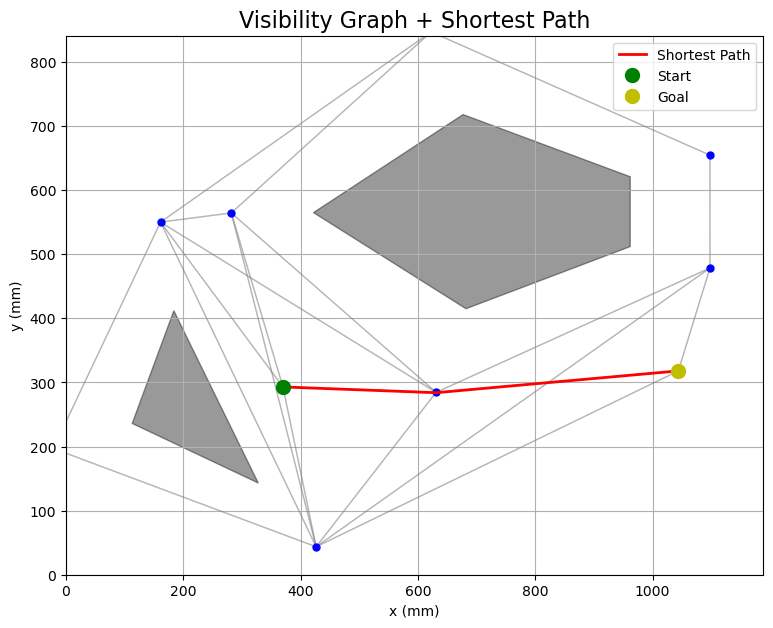

Press 'p' to close the plot.


In [ ]:
from main import *
await main()

## References

For the integration of this part, we used the listed references to guide us more into our work. 
- https://www.geeksforgeeks.org/dsa/orientation-3-ordered-points/
- https://www.geeksforgeeks.org/dsa/check-if-two-given-line-segments-intersect/
- Prof. Ferrari Trecate Giancarlo
- Exercise sessions in class

## AI Assistance Disclaimer
Parts of this work were supported by the use of AI tools (ChatGPT, Claude, and Google Gemini) for code assistance, editorial refinement, and improving the clarity of explanations.
The AI tools were used strictly as assistants, and the responsibility for the content, methodology, and results presented in this report remains entirely our own.

## Acknowledgment of External Input
Throughout the development of this project, we consulted a variety of external resources to inform our design decisions.
This included reviewing publicly available projects from previous years, seeking advice from classmates and peers, and discussing technical questions with teaching assistants.
While these interactions helped us better understand design choices and common pitfalls, all conceptual decisions, implementation steps, and final engineering solutions presented in this report were made independently by our team.